# Visualize Rates
### Import libraries

In [1]:
import os
import sys
import pickle
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm.notebook import tqdm

Visualization libraries

In [2]:
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
# %matplotlib qt

Global paths

In [3]:
# WORKSPACE
WORKSPACE = os.environ['WORKSPACE_PATH']
# PyCOMET
PyCOMET = WORKSPACE + '/ML/PyCOMET/pycomet/'
if importlib.util.find_spec('pycomet') is None:
    sys.path.append(os.path.abspath(PyCOMET))
# SurQCT
SurQCT = WORKSPACE + '/ML/PyCOMET/pycomet/examples/SurQCT/'
sys.path.append(os.path.abspath(SurQCT))
# Current Working Directory
CWD = os.getcwd()

In [4]:
# Output directory
out_dir = CWD + '/Output/VisualizeRates/'
if not os.path.exists(out_dir):
    os.makedirs(out_dir)

### Initialize PyCOMET model
Working case

In [5]:
case_dir = WORKSPACE + '/ML/PyCOMET/run/SurQCT/mimmo/O3_UMN/KInel/case.01/'
sys.path.append(os.path.abspath(case_dir))

In [6]:
os.chdir(case_dir)

Import additional libraries

In [7]:
from pycomet.utilities import utils
from pycomet.apps import functions as fun
# Inputs
import inputs
from inputs.general import flags

Compile model

In [8]:
# Load network architecture
net = fun._net(
    input_mod=inputs
)
# Finalize model
for k in ('train', 'save'):
    flags[k] = 0
flags['load'] = 1
model = fun._model(
    flags=flags,
    input_mod=inputs,
    net=net
)


[PyCOMET]: Initializing 'OpNN' network ...

[PyCOMET]: Building 'OpNN' network ...
Model: "SurQCT_OpNN"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 5)]          0                                            
__________________________________________________________________________________________________
input_2 (InputLayer)            [(None, 5)]          0                                            
__________________________________________________________________________________________________
normalization (Normalization)   (None, 5)            11          input_1[0][0]                    
__________________________________________________________________________________________________
normalization_1 (Normalization) (None, 5)            11          input_2[0][0]                    
____

In [9]:
os.chdir(CWD)

### Initialize SurQCT parameters
SurQCT model inputs

In [10]:
surqct_inp = case_dir + '/data_gen/InputData.py'
sys.path.append(os.path.dirname(surqct_inp))

import InputData

In [11]:
# Modifiy test input parameters
InputData.MinRateValue = 1.e-20
InputData.TTranVecTest = [1500., 5000., 10000., 20000.]

### Generating data
Import `RatesType` module

In [12]:
RatesType = __import__(
    f'surqct.src.RatesType.{InputData.NbAtoms}Atoms.{InputData.RatesType}',
    globals(),
    locals(),
    [InputData.RatesType],
    0
)

Read levels data

In [13]:
LevelsData, DiatData, NLevels = RatesType.read_levelsinfo(InputData, InputData.TTranVecTest)

[SurQCT]:    Reading Variables:  ['log_EVib', 'log_ERot', 'log_VMax', 'log_ro']
[SurQCT]:    Reading Molecule O2_UMN
[SurQCT]:    Reading Molecular Levels Data from: /home/zanardi/WORKSPACE//AirDatabase/Run0D/database/levels/modified//O2_UMN/VMin_VMax.csv
[SurQCT]:    Reading Diatomic Potential Data from: /home/zanardi/WORKSPACE//NeqPlasma/CoarseAIR/coarseair//dtb/Molecules//O2/UMN/FromUMN_Sorted.inp
[SurQCT]:    Reading Molecule O2_UMN
[SurQCT]:    Reading Molecular Levels Data from: /home/zanardi/WORKSPACE//AirDatabase/Run0D/database/levels/modified//O2_UMN/VMin_VMax.csv
[SurQCT]:    Reading Diatomic Potential Data from: /home/zanardi/WORKSPACE//NeqPlasma/CoarseAIR/coarseair//dtb/Molecules//O2/UMN/FromUMN_Sorted.inp


Sampling levels

In [14]:
# Predefined
iLevels = [1, 10, 32, 34, 35, 81, 82, 98, 1000, 2000, 3000, 4581, 6115]

# Random
iLevels = iLevels + list(np.random.choice(NLevels[0], size=10, replace=False) + 1)

# By rotational quantum number
JqnVec = [0]
for jqn in JqnVec:
    iLevels = iLevels + [idx+1 for idx in np.arange(NLevels[0]) if (DiatData[0]['jqn'].to_numpy(int)[idx] == jqn)]

InputData.iLevelsVecTest = np.unique(iLevels)

In [15]:
# Predefined
InputData.iLevelsVecTest = [1, 98, 3000, 4581, 4599, 6115]

Generate testing data

In [16]:
x_true, y_true = RatesType.generate_testingdata(InputData)
data_true = pd.concat([x_true, y_true], axis=1)

[SurQCT]:  Generating Labeled Test Data Points
[SurQCT]:    Reading Variables:  ['log_EVib', 'log_ERot', 'log_VMax', 'log_ro']
[SurQCT]:    Reading Molecule O2_UMN
[SurQCT]:    Reading Molecular Levels Data from: /home/zanardi/WORKSPACE//AirDatabase/Run0D/database/levels/modified//O2_UMN/VMin_VMax.csv
[SurQCT]:    Reading Diatomic Potential Data from: /home/zanardi/WORKSPACE//NeqPlasma/CoarseAIR/coarseair//dtb/Molecules//O2/UMN/FromUMN_Sorted.inp
[SurQCT]:    Reading Molecule O2_UMN
[SurQCT]:    Reading Molecular Levels Data from: /home/zanardi/WORKSPACE//AirDatabase/Run0D/database/levels/modified//O2_UMN/VMin_VMax.csv
[SurQCT]:    Reading Diatomic Potential Data from: /home/zanardi/WORKSPACE//NeqPlasma/CoarseAIR/coarseair//dtb/Molecules//O2/UMN/FromUMN_Sorted.inp
[SurQCT]:    Vector of Initial Levels:
[SurQCT]:    [1, 98, 3000, 4581, 4599, 6115]

[SurQCT]:    Translational Temperature: T = 1500 K
[SurQCT]:      Reading HDF5 File: '/home/zanardi/WORKSPACE//AirDatabase/HDF5/Orig/O3_UMN.

 33%|███▎      | 2/6 [00:00<00:00, 11.16it/s]


[SurQCT]:    Translational Temperature: T = 5000 K
[SurQCT]:      Reading HDF5 File: '/home/zanardi/WORKSPACE//AirDatabase/HDF5/Orig/O3_UMN.hdf5' for Excitation Rates at Temperature 5000 K


 33%|███▎      | 2/6 [00:00<00:00, 11.05it/s]


[SurQCT]:    Translational Temperature: T = 10000 K
[SurQCT]:      Reading HDF5 File: '/home/zanardi/WORKSPACE//AirDatabase/HDF5/Orig/O3_UMN.hdf5' for Excitation Rates at Temperature 10000 K


 33%|███▎      | 2/6 [00:00<00:00, 11.37it/s]


[SurQCT]:    Translational Temperature: T = 20000 K
[SurQCT]:      Reading HDF5 File: '/home/zanardi/WORKSPACE//AirDatabase/HDF5/Orig/O3_UMN.hdf5' for Excitation Rates at Temperature 20000 K


100%|██████████| 6/6 [00:00<00:00, 11.49it/s]


Generate prediction data

In [17]:
x_pred, y_pred = RatesType.generate_predictiondata(InputData, model.net, Labeled=True)
data_pred = pd.concat([x_pred, y_pred], axis=1)

  0%|          | 0/6 [00:00<?, ?it/s]

[SurQCT]:  Generating Prediction Data
[SurQCT]:    Reading Variables:  ['log_EVib', 'log_ERot', 'log_VMax', 'log_ro']
[SurQCT]:    Reading Molecule O2_UMN
[SurQCT]:    Reading Molecular Levels Data from: /home/zanardi/WORKSPACE//AirDatabase/Run0D/database/levels/modified//O2_UMN/VMin_VMax.csv
[SurQCT]:    Reading Diatomic Potential Data from: /home/zanardi/WORKSPACE//NeqPlasma/CoarseAIR/coarseair//dtb/Molecules//O2/UMN/FromUMN_Sorted.inp
[SurQCT]:    Reading Molecule O2_UMN
[SurQCT]:    Reading Molecular Levels Data from: /home/zanardi/WORKSPACE//AirDatabase/Run0D/database/levels/modified//O2_UMN/VMin_VMax.csv
[SurQCT]:    Reading Diatomic Potential Data from: /home/zanardi/WORKSPACE//NeqPlasma/CoarseAIR/coarseair//dtb/Molecules//O2/UMN/FromUMN_Sorted.inp
[SurQCT]:    Vector of Initial Levels:
[SurQCT]:    [1, 98, 3000, 4581, 4599, 6115]

[SurQCT]:    Translational Temperature: T = 1500 K


  0%|          | 0/6 [00:00<?, ?it/s]


[SurQCT]:    Translational Temperature: T = 5000 K


  0%|          | 0/6 [00:00<?, ?it/s]


[SurQCT]:    Translational Temperature: T = 10000 K


  0%|          | 0/6 [00:00<?, ?it/s]


[SurQCT]:    Translational Temperature: T = 20000 K


100%|██████████| 6/6 [00:01<00:00,  4.25it/s]


### Plotting rates

Temperature T = 1500K:   0%|          | 0/6 [00:00<?, ?it/s]

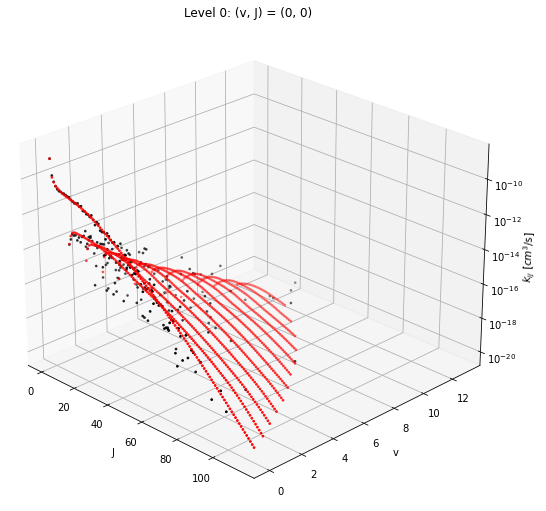

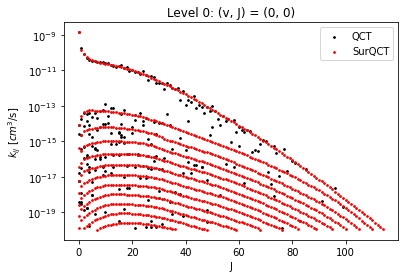

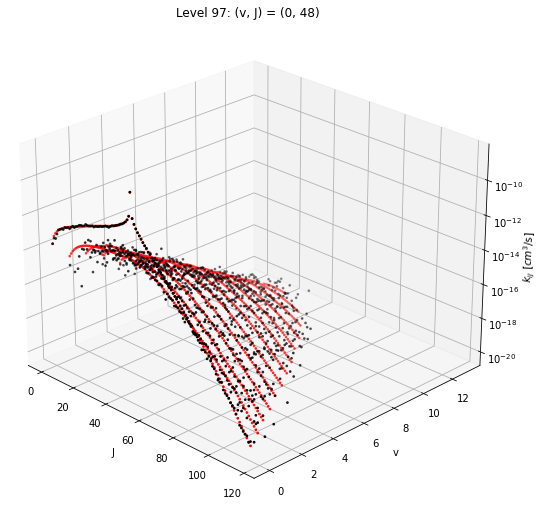

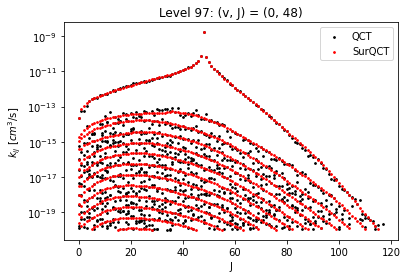

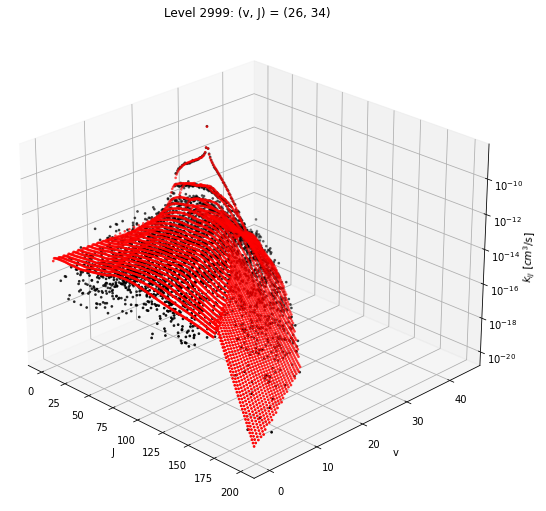

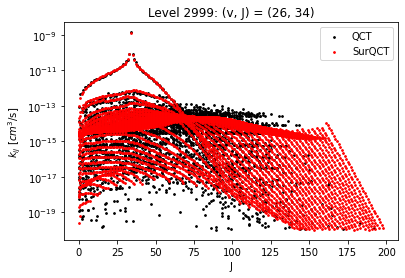

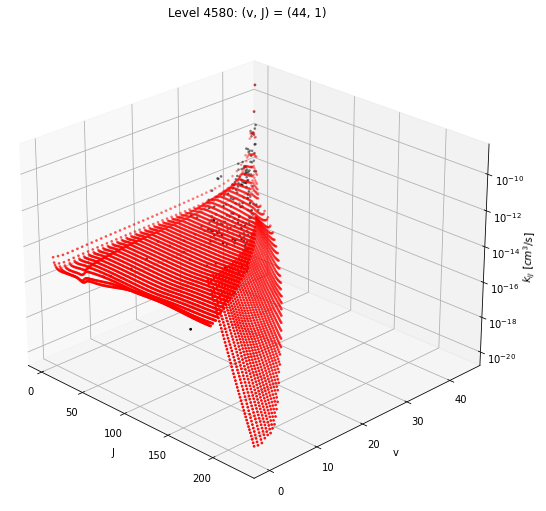

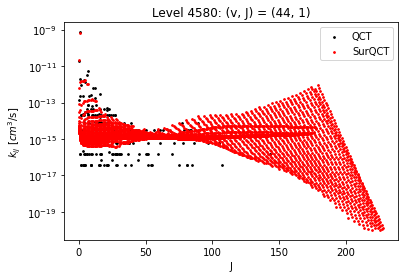

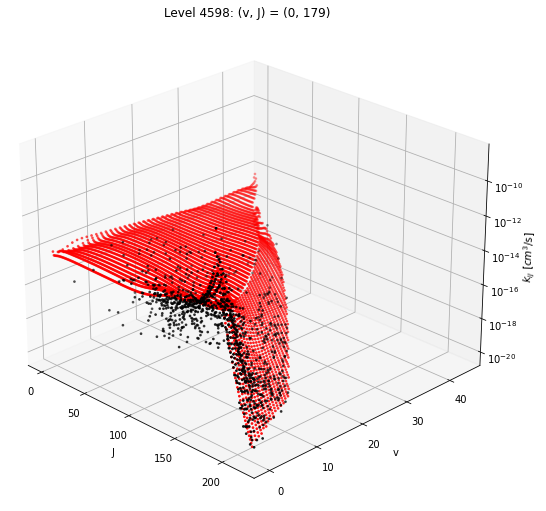

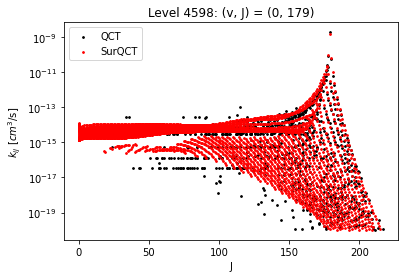

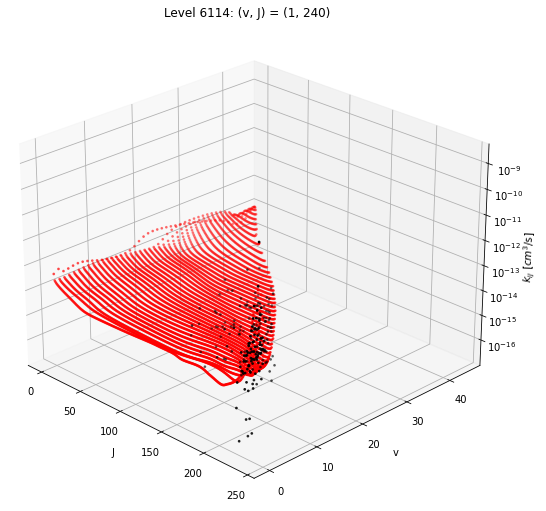

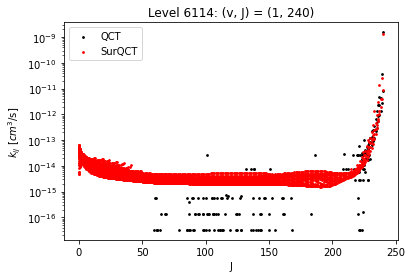

Temperature T = 5000K:   0%|          | 0/6 [00:00<?, ?it/s]

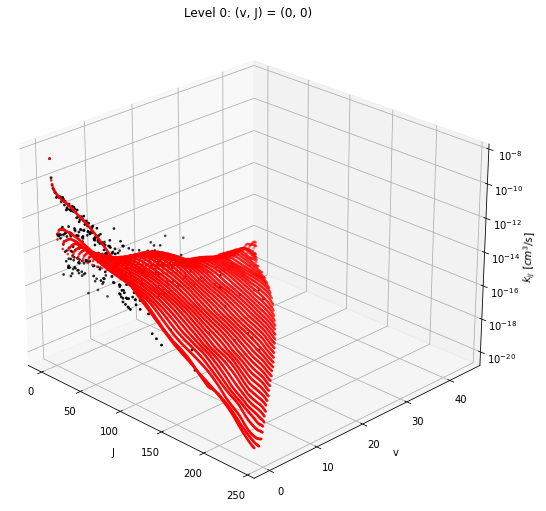

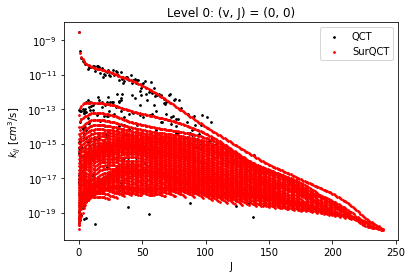

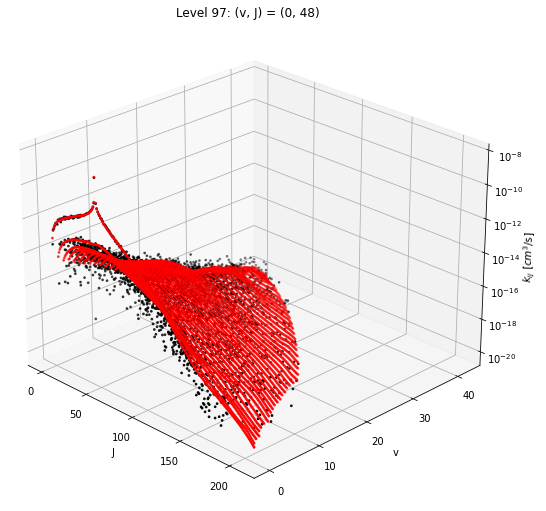

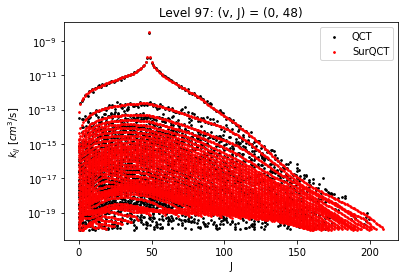

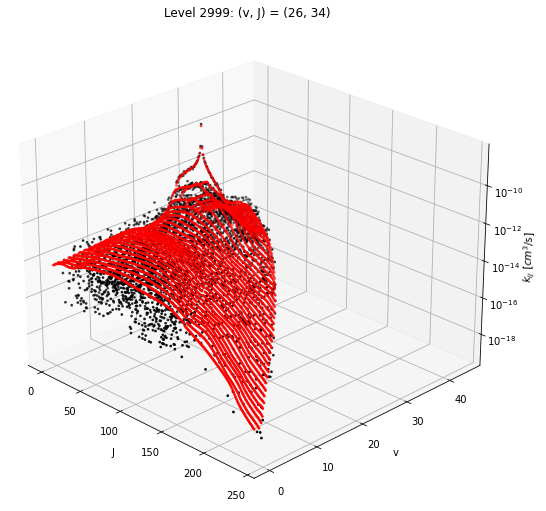

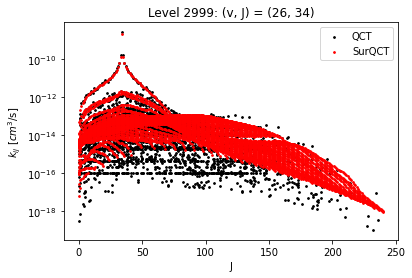

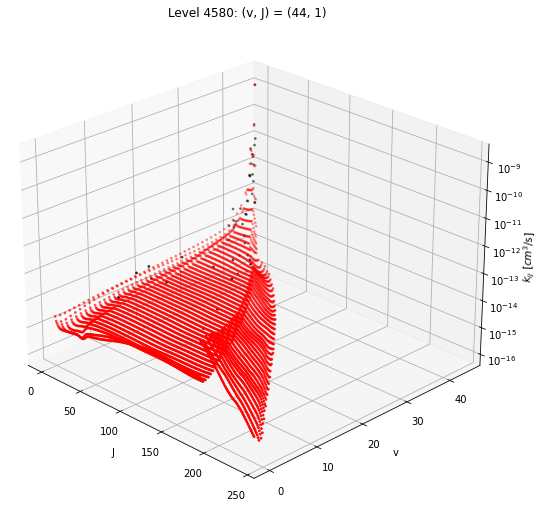

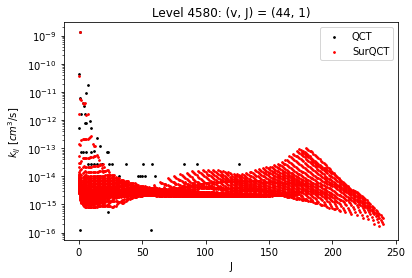

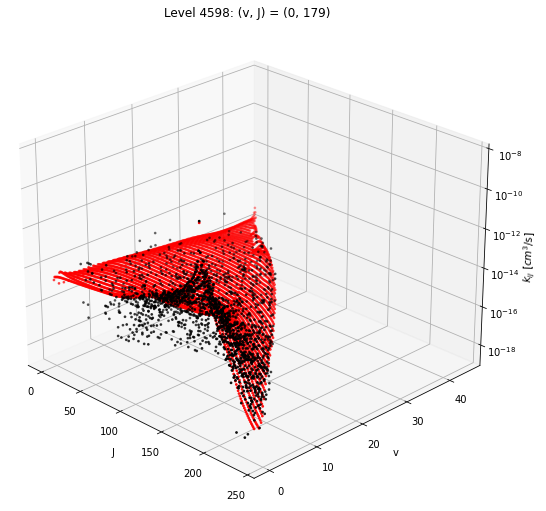

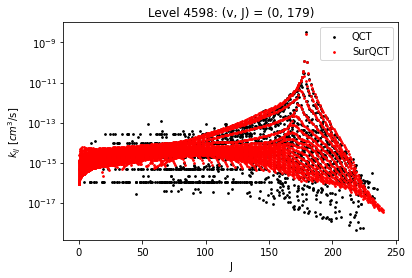

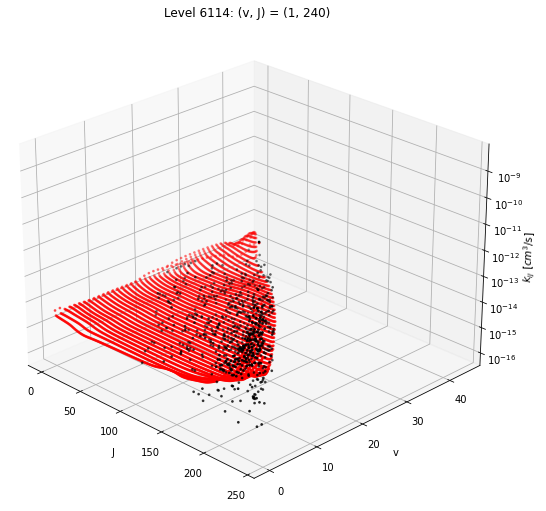

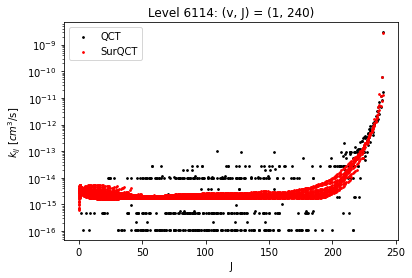

Temperature T = 10000K:   0%|          | 0/6 [00:00<?, ?it/s]

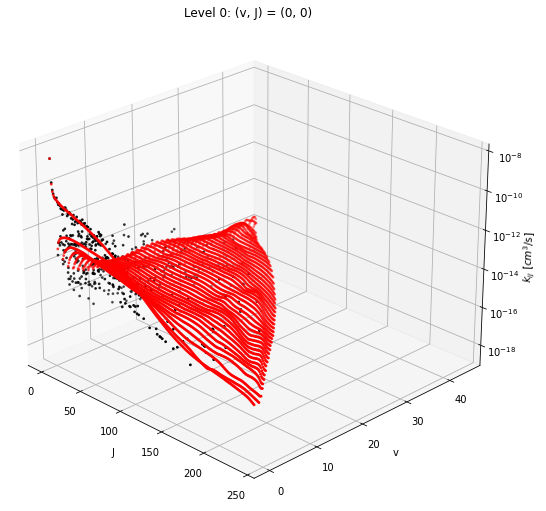

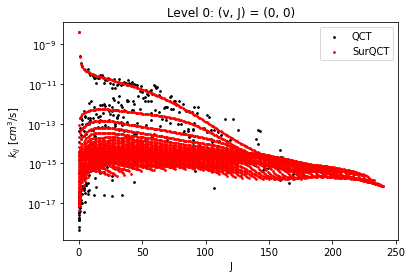

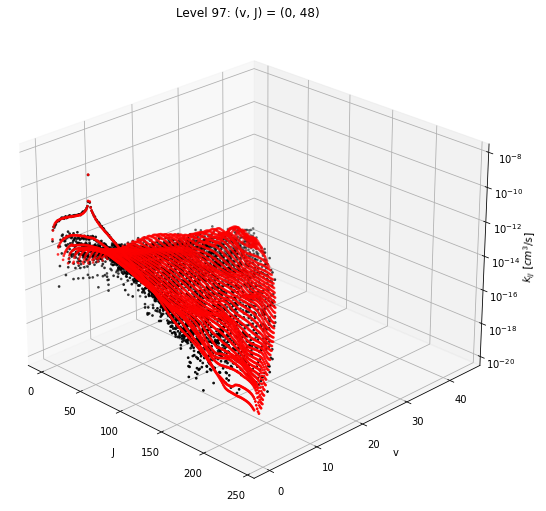

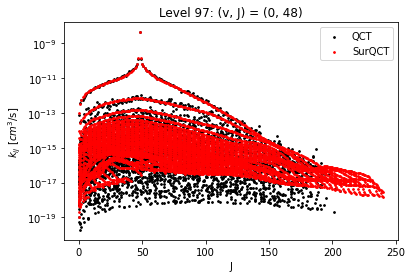

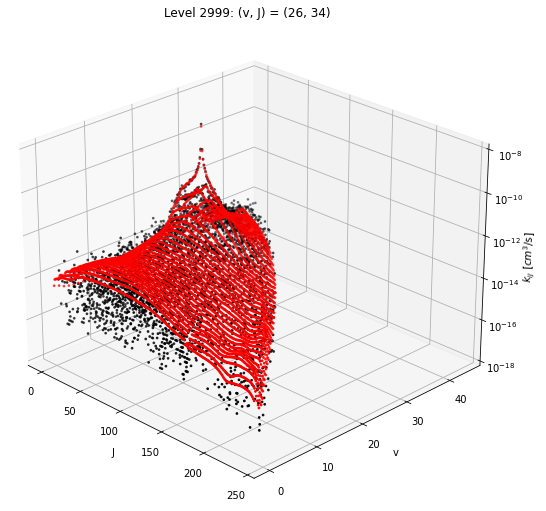

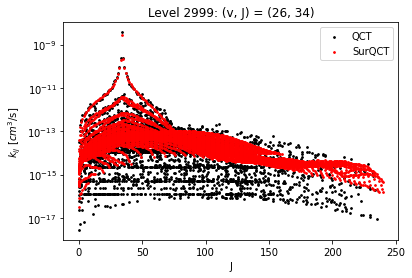

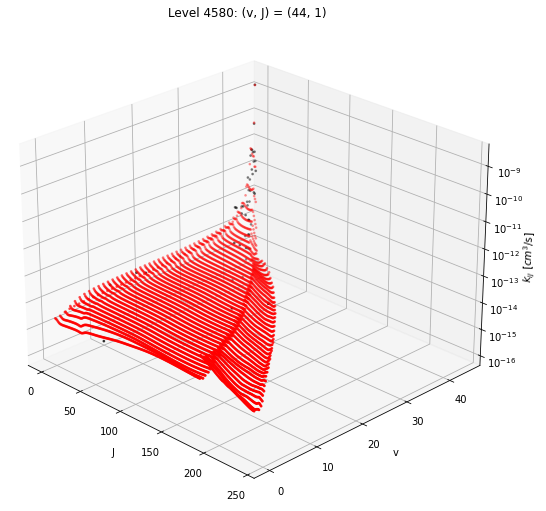

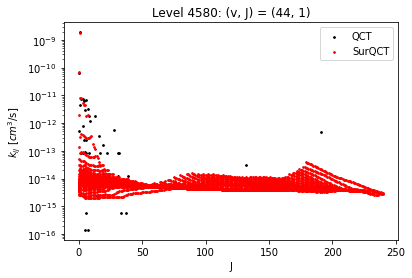

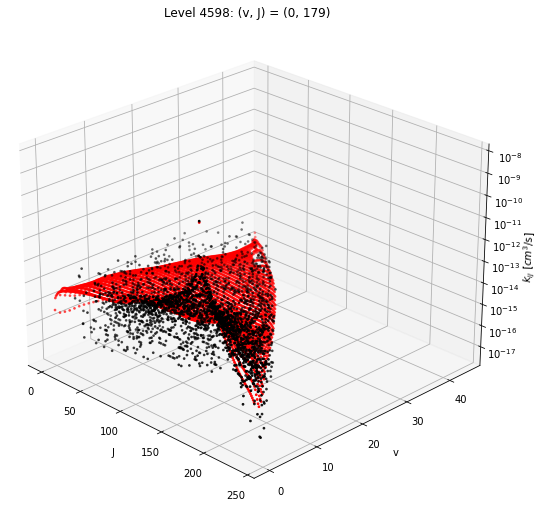

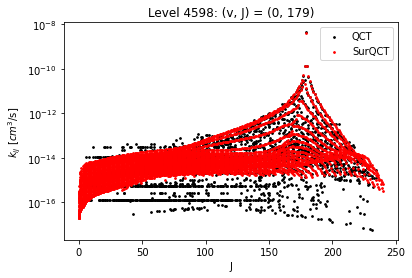

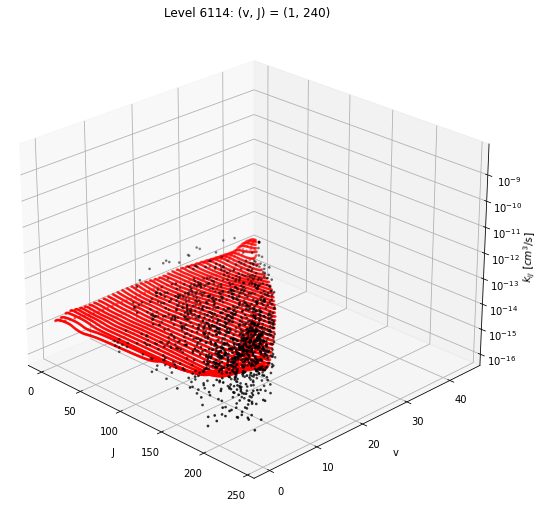

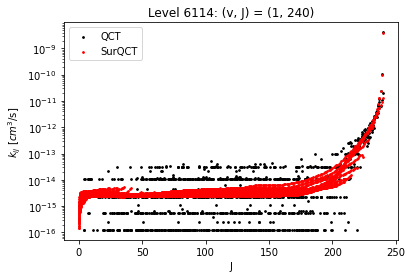

Temperature T = 20000K:   0%|          | 0/6 [00:00<?, ?it/s]

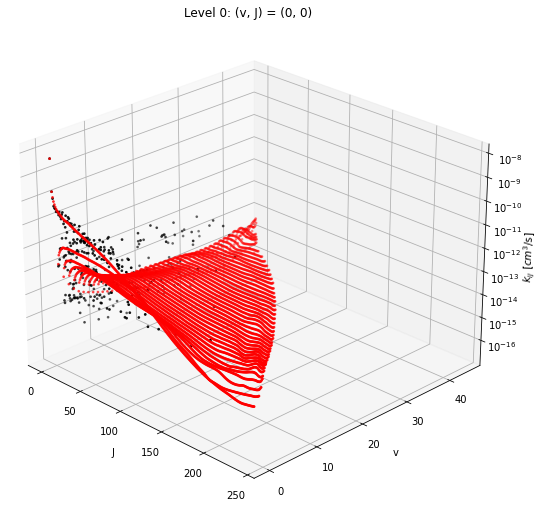

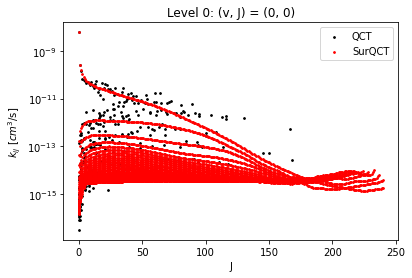

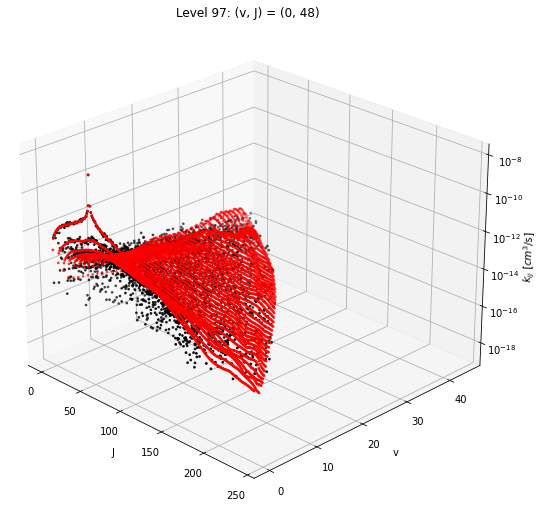

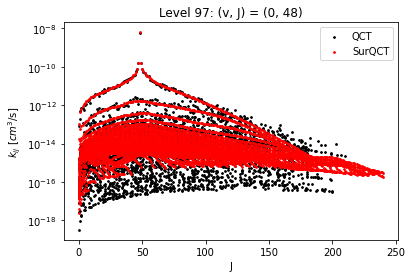

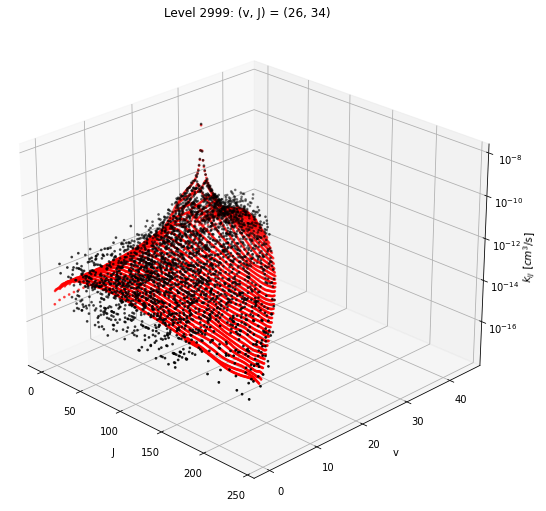

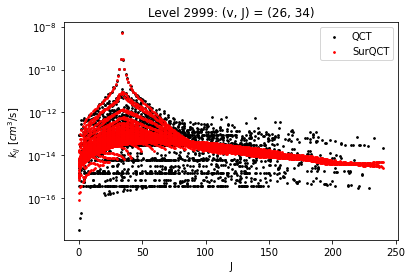

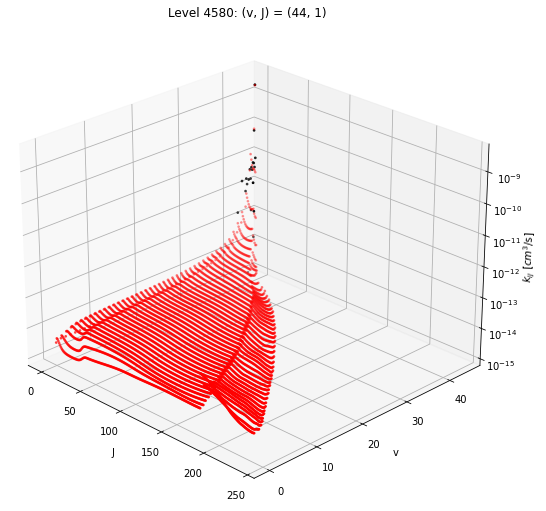

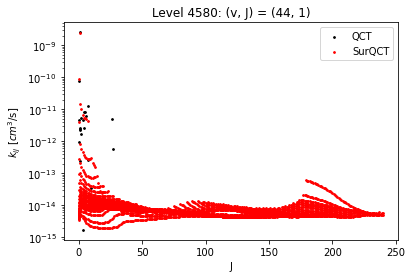

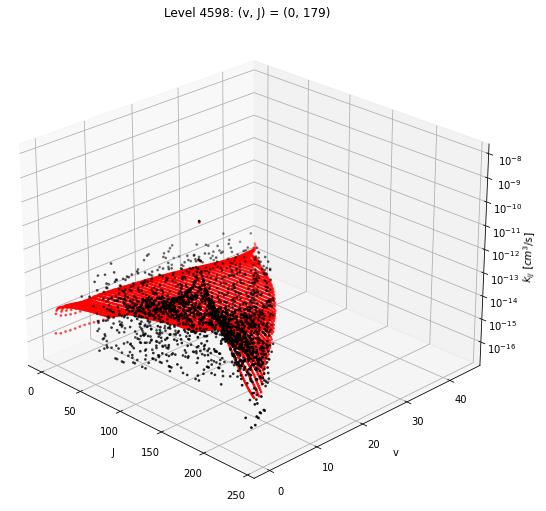

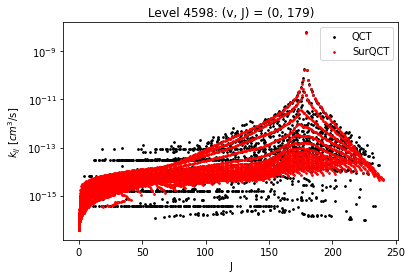

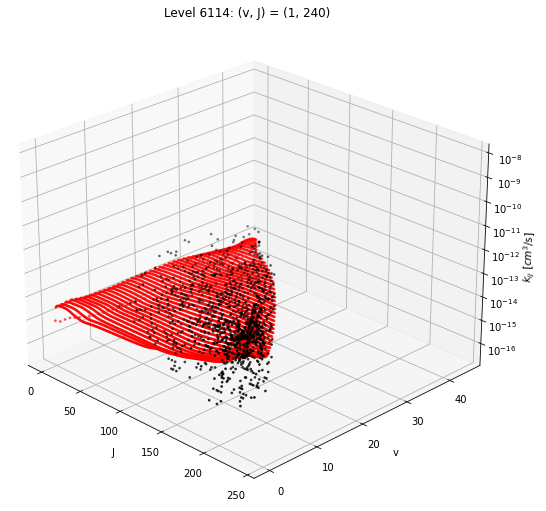

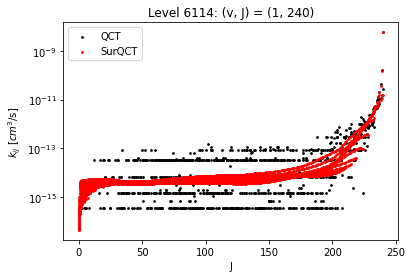

In [18]:
for T in InputData.TTranVecTest:
    paths = {k: out_dir + f'/T{int(T)}K/{k}/' for k in ('2D','3D')}
    for path in paths.values():
        if not os.path.exists(path):
            os.makedirs(path)
    for iIdx in tqdm(InputData.iLevelsVecTest, desc='Temperature T = ' + str(int(T)) + 'K'):
        iIdx = iIdx-1
        # True values
        TrueData = data_true.loc[(data_true['TTran_i'] == T) & (data_true['Idx_i'] == iIdx) & (data_true['KExcit'] >= InputData.MinRateValue)]
        TrueData = (TrueData['Idx_j'].to_numpy().astype(int), TrueData['KExcit'].to_numpy())
        # Pred values
        PredData = data_pred.loc[(data_pred['TTran_i'] == T) & (data_pred['Idx_i'] == iIdx) & (data_pred['KExcit'] >= InputData.MinRateValue)]
        PredData = (PredData['Idx_j'].to_numpy().astype(int), PredData['KExcit'].to_numpy())
        # Plotting
        RatesType.plot_prediction3D(paths['3D'], iIdx, DiatData, TrueData, PredData)
        plt.show()
        plt.close()
        RatesType.plot_prediction2D(paths['2D'], iIdx, DiatData, TrueData, PredData)
        plt.show()
        plt.close()

In [19]:
# # Get (v,J) of high value reconstructed endothermic rates

# # Initial state
# iIdx = 4581
# # Final state
# vqnRange = [0, 44]
# jqnRange = [150, 240]

# jIdxVec = data_pred['Idx_j'].to_numpy(dtype=int)
# jqn  = DiatData[1]['jqn'].to_numpy()[jIdxVec].astype(int)
# vqn  = DiatData[1]['vqn'].to_numpy()[jIdxVec].astype(int)

# data_pred_sub = data_pred.loc[(vqnRange[0] <= vqn) & (vqn <= vqnRange[1]) & (jqnRange[0] <= jqn) & (jqn <= jqnRange[1]) & (data_pred['Idx_i'] == iIdx - 1)]
# jIdx = data_pred_sub['Idx_j'].to_numpy(dtype=int)[np.argmax(data_pred_sub['KExcit'])]

# vqn, jqn = DiatData[1][['jqn','vqn']].to_numpy()[jIdx].astype(int)

# print(f"Level {jIdx}: (v, J) = ({vqn}, {jqn})")